In [1]:
# ==============================================================================
# YÊU CẦU 1: Đọc dữ liệu từ file alzheimers_disease_data.csv. 
# Kiểm tra cấu trúc dữ liệu, xử lý giá trị thiếu và làm sạch dữ liệu.
# ==============================================================================
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# 1. Đọc file dữ liệu CSV bằng thư viện Pandas (Lesson 02)
data = pd.read_csv('alzheimers_disease_data.csv')
print(f"Kích thước ban đầu của tập dữ liệu: {data.shape[0]} hàng, {data.shape[1]} cột")

# 2. Hiển thị 5 hàng đầu tiên
print("\n--- 5 HÀNG ĐẦU TIÊN CỦA BỘ DỮ LIỆU ---")
display(data.head(5))

# 3. Loại bỏ các cột định danh không mang giá trị dự báo sinh học
data_cleaned = data.drop(columns=['PatientID', 'DoctorInCharge'])
print(f"Kích thước sau khi loại bỏ 'PatientID' và 'DoctorInCharge': {data_cleaned.shape}")

# 4. Kiểm tra cấu trúc thông tin (df.info()) và giá trị thiếu (isna())
print("\n--- KIỂM TRA THÔNG TIN VÀ GIÁ TRỊ THIẾU ---")
print("Tổng số giá trị khuyết thiếu (NaN):", data_cleaned.isna().sum().sum())

# 5. Xử lý ngoại lai (Outliers) bằng phương pháp khoảng tứ phân vị IQR
def handle_outliers_iqr(df, cols):
    df_clean = df.copy()
    for col in cols:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)]
    return df_clean

num_features = ['Age', 'BMI', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'MMSE', 'ADL']
data_cleaned = handle_outliers_iqr(data_cleaned, num_features)
print(f"Số lượng bệnh nhân sau khi làm sạch ngoại lai IQR: {len(data_cleaned)} mẫu")


Kích thước ban đầu của tập dữ liệu: 2149 hàng, 35 cột

--- 5 HÀNG ĐẦU TIÊN CỦA BỘ DỮ LIỆU ---


,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1,0,0,XXXConfid
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0,1,0,XXXConfid
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1,0,0,XXXConfid
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0,0,0,XXXConfid
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1,0,0,XXXConfid


Kích thước sau khi loại bỏ 'PatientID' và 'DoctorInCharge': (2149, 33)

--- KIỂM TRA THÔNG TIN VÀ GIÁ TRỊ THIẾU ---
Tổng số giá trị khuyết thiếu (NaN): 0
Số lượng bệnh nhân sau khi làm sạch ngoại lai IQR: 2149 mẫu


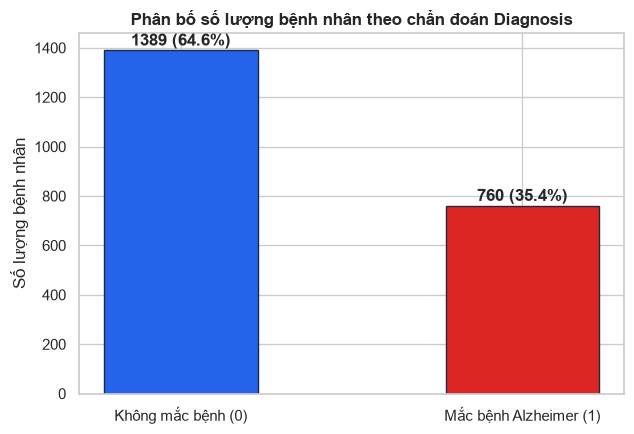

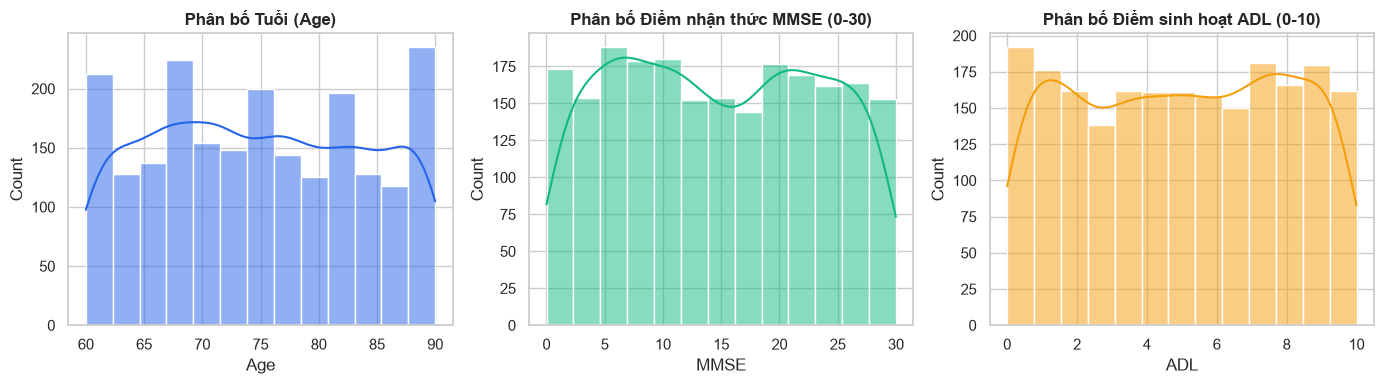

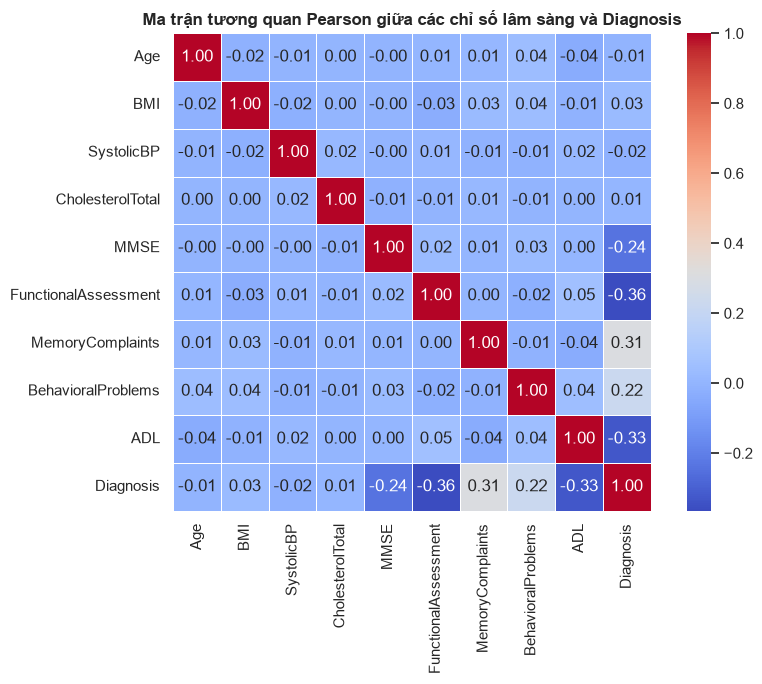

In [2]:
# ==============================================================================
# YÊU CẦU 2: Khám phá và trực quan hoá dữ liệu (Data Visualization & EDA)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'

# 1. Biểu đồ đếm số lượng và tỷ lệ biến mục tiêu chẩn đoán (Diagnosis)
plt.figure(figsize=(6.5, 4.5))
counts = data_cleaned['Diagnosis'].value_counts()
bars = plt.bar(['Không mắc bệnh (0)', 'Mắc bệnh Alzheimer (1)'], counts.values, 
               color=['#2563eb', '#dc2626'], width=0.45, edgecolor='#1e293b')
plt.title('Phân bố số lượng bệnh nhân theo chẩn đoán Diagnosis', fontsize=12, weight='bold')
plt.ylabel('Số lượng bệnh nhân')
for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(data_cleaned)) * 100
    plt.text(bar.get_x() + bar.get_width()/2, yval + 20, f"{yval} ({pct:.1f}%)", ha='center', weight='bold')
plt.tight_layout()
plt.show()

# 2. Biểu đồ phân phối các đặc trưng liên tục then chốt
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(data=data_cleaned, x='Age', kde=True, ax=axes[0], color='#2563eb')
axes[0].set_title('Phân bố Tuổi (Age)', weight='bold')

sns.histplot(data=data_cleaned, x='MMSE', kde=True, ax=axes[1], color='#10b981')
axes[1].set_title('Phân bố Điểm nhận thức MMSE (0-30)', weight='bold')

sns.histplot(data=data_cleaned, x='ADL', kde=True, ax=axes[2], color='#f59e0b')
axes[2].set_title('Phân bố Điểm sinh hoạt ADL (0-10)', weight='bold')
plt.tight_layout()
plt.show()

# 3. Ma trận tương quan giữa các đặc trưng y sinh và nguy cơ Alzheimer
key_cols = ['Age', 'BMI', 'SystolicBP', 'CholesterolTotal', 'MMSE', 
            'FunctionalAssessment', 'MemoryComplaints', 'BehavioralProblems', 'ADL', 'Diagnosis']
plt.figure(figsize=(9, 7))
corr = data_cleaned[key_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Ma trận tương quan Pearson giữa các chỉ số lâm sàng và Diagnosis', fontsize=12, weight='bold')
plt.tight_layout()
plt.show()


In [3]:
# ==============================================================================
# YÊU CẦU 3: Chuẩn bị dữ liệu huấn luyện
# (Tách X, y, chia Train/Test 80:20, Chuẩn hóa StandardScaler và Cân bằng SMOTE)
# ==============================================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

# 1. Tách biến đặc trưng (X) và nhãn mục tiêu (y)
X = data_cleaned.drop(columns=['Diagnosis'])
y = data_cleaned['Diagnosis']

# 2. Chia dữ liệu thành tập huấn luyện (80%) và tập kiểm thử (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Số lượng mẫu huấn luyện (Train):", len(X_train))
print("Số lượng mẫu kiểm thử (Test):   ", len(X_test))

# 3. Chuẩn hóa dữ liệu bằng StandardScaler (Z-Score Normalization theo Lesson 05)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Cân bằng dữ liệu tập Train bằng kỹ thuật SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("\nPhân phối nhãn trước SMOTE trong y_train:\n", y_train.value_counts().to_dict())
print("Phân phối nhãn sau SMOTE trong y_train:  \n", pd.Series(y_train_smote).value_counts().to_dict())


Số lượng mẫu huấn luyện (Train): 1719
Số lượng mẫu kiểm thử (Test):    430

Phân phối nhãn trước SMOTE trong y_train:
 {0: 1111, 1: 608}
Phân phối nhãn sau SMOTE trong y_train:  
 {0: 1111, 1: 1111}


In [4]:
# ==============================================================================
# YÊU CẦU 4: Huấn luyện, đánh giá và hiển thị giá trị: Loss, Accuracy, Precision, 
# Recall, F1-Score với giải thuật K-Nearest Neighbor (KNN).
# (Cơ sở lý thuyết: Lesson 05 - Classification algorithm)
# ==============================================================================
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss, confusion_matrix, classification_report

# 1. Khởi tạo và huấn luyện mô hình KNN
knn_model = KNeighborsClassifier(n_neighbors=9, metric='manhattan', weights='distance')
knn_model.fit(X_train_smote, y_train_smote)

# 2. Dự đoán trên tập testing
y_pred_knn = knn_model.predict(X_test_scaled)
y_pred_prob_knn = knn_model.predict_proba(X_test_scaled)

# 3. Tính toán các chỉ số đánh giá
knn_loss = log_loss(y_test, y_pred_prob_knn)
knn_acc = accuracy_score(y_test, y_pred_knn)
knn_prec = precision_score(y_test, y_pred_knn)
knn_rec = recall_score(y_test, y_pred_knn)
knn_f1 = f1_score(y_test, y_pred_knn)

# 4. Hiển thị giá trị
print("--- K-NEAREST NEIGHBOR (KNN) ---")
print(f"Loss (Log-loss): {knn_loss:.4f}")
print(f"Accuracy:        {knn_acc:.4f} ({knn_acc*100:.2f}%)")
print(f"Precision:       {knn_prec:.4f}")
print(f"Recall:          {knn_rec:.4f}")
print(f"F1-Score:        {knn_f1:.4f}")
print("\nMa trận nhầm lẫn (Confusion Matrix):\n", confusion_matrix(y_test, y_pred_knn))
print("\nClassification Report:\n", classification_report(y_test, y_pred_knn))


--- K-NEAREST NEIGHBOR (KNN) ---
Loss (Log-loss): 0.5410
Accuracy:        0.6953 (69.53%)
Precision:       0.5550
Recall:          0.6974
F1-Score:        0.6181

Ma trận nhầm lẫn (Confusion Matrix):
 [[193  85]
 [ 46 106]]

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.69      0.75       278
           1       0.55      0.70      0.62       152

    accuracy                           0.70       430
   macro avg       0.68      0.70      0.68       430
weighted avg       0.72      0.70      0.70       430



In [5]:
# ==============================================================================
# YÊU CẦU 5: Huấn luyện, đánh giá và hiển thị giá trị: Loss, Accuracy, Precision, 
# Recall, F1-Score với giải thuật Support Vector Machine (SVM / SVC).
# (Cơ sở lý thuyết: Lesson 05 - Classification algorithm)
# ==============================================================================
from sklearn.svm import SVC

# 1. Khởi tạo và huấn luyện mô hình Support Vector Machine
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)
svm_model.fit(X_train_smote, y_train_smote)

# 2. Dự đoán trên tập testing
y_pred_svm = svm_model.predict(X_test_scaled)
y_pred_prob_svm = svm_model.predict_proba(X_test_scaled)

# 3. Tính toán các chỉ số đánh giá
svm_loss = log_loss(y_test, y_pred_prob_svm)
svm_acc = accuracy_score(y_test, y_pred_svm)
svm_prec = precision_score(y_test, y_pred_svm)
svm_rec = recall_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)

# 4. Hiển thị giá trị
print("--- SUPPORT VECTOR MACHINE (SVM) ---")
print(f"Loss (Log-loss): {svm_loss:.4f}")
print(f"Accuracy:        {svm_acc:.4f} ({svm_acc*100:.2f}%)")
print(f"Precision:       {svm_prec:.4f}")
print(f"Recall:          {svm_rec:.4f}")
print(f"F1-Score:        {svm_f1:.4f}")
print("\nMa trận nhầm lẫn (Confusion Matrix):\n", confusion_matrix(y_test, y_pred_svm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))


--- SUPPORT VECTOR MACHINE (SVM) ---
Loss (Log-loss): 0.3872
Accuracy:        0.8535 (85.35%)
Precision:       0.7834
Recall:          0.8092
F1-Score:        0.7961

Ma trận nhầm lẫn (Confusion Matrix):
 [[244  34]
 [ 29 123]]

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.88      0.89       278
           1       0.78      0.81      0.80       152

    accuracy                           0.85       430
   macro avg       0.84      0.84      0.84       430
weighted avg       0.85      0.85      0.85       430



In [6]:
# ==============================================================================
# YÊU CẦU 6: Huấn luyện, đánh giá và hiển thị giá trị: Loss, Accuracy, Precision, 
# Recall, F1-Score với giải thuật Decision Tree.
# (Cơ sở lý thuyết: Lesson 05 - Classification algorithm)
# ==============================================================================
from sklearn.tree import DecisionTreeClassifier

# 1. Khởi tạo và huấn luyện mô hình Decision Tree (criterion='gini' theo slide)
dt_model = DecisionTreeClassifier(criterion='gini', max_depth=10, random_state=42)
dt_model.fit(X_train_smote, y_train_smote)

# 2. Dự đoán trên tập testing
y_pred_dt = dt_model.predict(X_test_scaled)
y_pred_prob_dt = dt_model.predict_proba(X_test_scaled)

# 3. Tính toán các chỉ số đánh giá
dt_loss = log_loss(y_test, y_pred_prob_dt)
dt_acc = accuracy_score(y_test, y_pred_dt)
dt_prec = precision_score(y_test, y_pred_dt)
dt_rec = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)

# 4. Hiển thị giá trị
print("--- DECISION TREE ---")
print(f"Loss (Log-loss): {dt_loss:.4f}")
print(f"Accuracy:        {dt_acc:.4f} ({dt_acc*100:.2f}%)")
print(f"Precision:       {dt_prec:.4f}")
print(f"Recall:          {dt_rec:.4f}")
print(f"F1-Score:        {dt_f1:.4f}")
print("\nMa trận nhầm lẫn (Confusion Matrix):\n", confusion_matrix(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))


--- DECISION TREE ---
Loss (Log-loss): 2.8071
Accuracy:        0.9000 (90.00%)
Precision:       0.8471
Recall:          0.8750
F1-Score:        0.8608

Ma trận nhầm lẫn (Confusion Matrix):
 [[254  24]
 [ 19 133]]

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.91      0.92       278
           1       0.85      0.88      0.86       152

    accuracy                           0.90       430
   macro avg       0.89      0.89      0.89       430
weighted avg       0.90      0.90      0.90       430



In [7]:
# ==============================================================================
# YÊU CẦU 7: Huấn luyện, đánh giá và hiển thị giá trị: Loss, Accuracy, Precision, 
# Recall, F1-Score với giải thuật Random Forest (Ensemble Learning).
# (Cơ sở lý thuyết: Lesson 06 - Regression & Ensemble algorithms)
# ==============================================================================
from sklearn.ensemble import RandomForestClassifier

# 1. Khởi tạo và huấn luyện mô hình Random Forest (200 cây quyết định, criterion='gini')
rf_model = RandomForestClassifier(n_estimators=200, criterion='gini', max_depth=20, random_state=42)
rf_model.fit(X_train_smote, y_train_smote)

# 2. Dự đoán trên tập testing
y_pred_rf = rf_model.predict(X_test_scaled)
y_pred_prob_rf = rf_model.predict_proba(X_test_scaled)

# 3. Tính toán các chỉ số đánh giá
rf_loss = log_loss(y_test, y_pred_prob_rf)
rf_acc = accuracy_score(y_test, y_pred_rf)
rf_prec = precision_score(y_test, y_pred_rf)
rf_rec = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

# 4. Hiển thị giá trị
print("--- RANDOM FOREST CLASSIFIER ---")
print(f"Loss (Log-loss): {rf_loss:.4f}")
print(f"Accuracy:        {rf_acc:.4f} ({rf_acc*100:.2f}%)")
print(f"Precision:       {rf_prec:.4f}")
print(f"Recall:          {rf_rec:.4f}")
print(f"F1-Score:        {rf_f1:.4f}")
print("\nMa trận nhầm lẫn (Confusion Matrix):\n", confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))


--- RANDOM FOREST CLASSIFIER ---
Loss (Log-loss): 0.3173
Accuracy:        0.9419 (94.19%)
Precision:       0.9441
Recall:          0.8882
F1-Score:        0.9153

Ma trận nhầm lẫn (Confusion Matrix):
 [[270   8]
 [ 17 135]]

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.97      0.96       278
           1       0.94      0.89      0.92       152

    accuracy                           0.94       430
   macro avg       0.94      0.93      0.94       430
weighted avg       0.94      0.94      0.94       430



In [8]:
# ==============================================================================
# YÊU CẦU 8: Huấn luyện và đánh giá với các thuật toán mở rộng trong bài giảng:
# Naïve Bayes, Logistic Regression và XGBoost.
# ==============================================================================
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# 1. Naïve Bayes (GaussianNB theo Lesson 05)
nb_model = GaussianNB()
nb_model.fit(X_train_smote, y_train_smote)
y_pred_nb = nb_model.predict(X_test_scaled)
nb_acc = accuracy_score(y_test, y_pred_nb)
nb_f1 = f1_score(y_test, y_pred_nb)

# 2. Logistic Regression (Lesson 05)
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_smote, y_train_smote)
y_pred_lr = lr_model.predict(X_test_scaled)
lr_acc = accuracy_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)

# 3. XGBoost (Lesson 06)
xgb_model = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, random_state=42)
xgb_model.fit(X_train_smote, y_train_smote)
y_pred_xgb = xgb_model.predict(X_test_scaled)
xgb_acc = accuracy_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)

print(f"Naïve Bayes:         Accuracy = {nb_acc:.4f} | F1 = {nb_f1:.4f}")
print(f"Logistic Regression: Accuracy = {lr_acc:.4f} | F1 = {lr_f1:.4f}")
print(f"XGBoost:             Accuracy = {xgb_acc:.4f} | F1 = {xgb_f1:.4f}")


Naïve Bayes:         Accuracy = 0.7860 | F1 = 0.7212
Logistic Regression: Accuracy = 0.8163 | F1 = 0.7670
XGBoost:             Accuracy = 0.9488 | F1 = 0.9267


=== BẢNG SO SÁNH HIỆU NĂNG CÁC GIẢI THUẬT HỌC MÁY ===


,Giải thuật,Accuracy,Precision,Recall,F1-Score,ROC-AUC
6,XGBoost,0.9488,0.9392,0.9145,0.9267,0.9439
3,Random Forest,0.9419,0.9441,0.8882,0.9153,0.9380
2,Decision Tree,0.9000,0.8471,0.8750,0.8608,0.8695
1,Support Vector Machine (SVM),0.8535,0.7834,0.8092,0.7961,0.8972
5,Logistic Regression,0.8163,0.6952,0.8553,0.7670,0.8866
4,Naïve Bayes,0.7860,0.6685,0.7829,0.7212,0.8465
0,K-Nearest Neighbor (KNN),0.6953,0.5550,0.6974,0.6181,0.7837


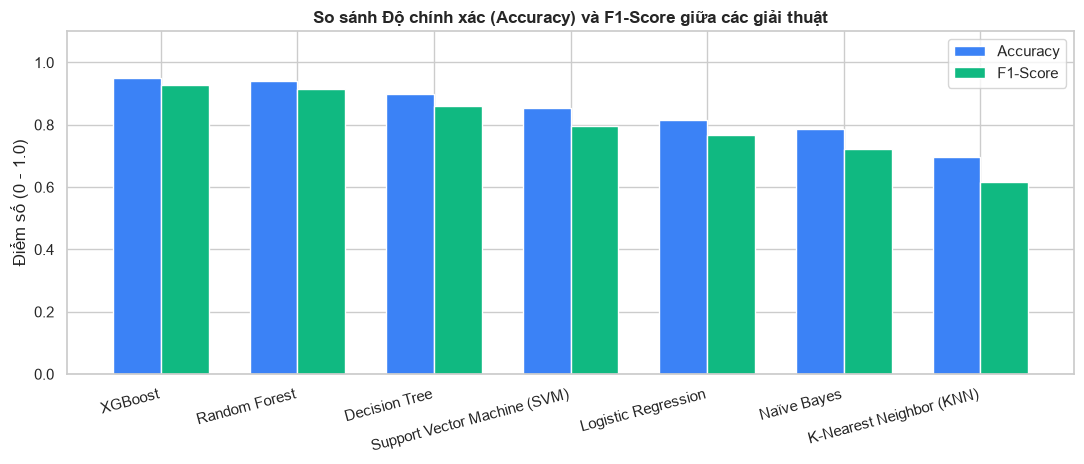


=> KẾT LUẬN: Giải thuật cho kết quả tốt nhất là 'XGBoost' với Accuracy đạt 94.88%


In [9]:
# ==============================================================================
# YÊU CẦU 9: So sánh tổng hợp hiệu năng các giải thuật trên tập kiểm thử độc lập
# ==============================================================================
from sklearn.metrics import roc_auc_score

comparison_data = {
    "Giải thuật": [
        "K-Nearest Neighbor (KNN)",
        "Support Vector Machine (SVM)",
        "Decision Tree",
        "Random Forest",
        "Naïve Bayes",
        "Logistic Regression",
        "XGBoost"
    ],
    "Accuracy": [
        knn_acc, svm_acc, dt_acc, rf_acc, nb_acc, lr_acc, xgb_acc
    ],
    "Precision": [
        knn_prec, svm_prec, dt_prec, rf_prec,
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_xgb)
    ],
    "Recall": [
        knn_rec, svm_rec, dt_rec, rf_rec,
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_xgb)
    ],
    "F1-Score": [
        knn_f1, svm_f1, dt_f1, rf_f1, nb_f1, lr_f1, xgb_f1
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_pred_prob_knn[:, 1]),
        roc_auc_score(y_test, y_pred_prob_svm[:, 1]),
        roc_auc_score(y_test, y_pred_prob_dt[:, 1]),
        roc_auc_score(y_test, y_pred_prob_rf[:, 1]),
        roc_auc_score(y_test, nb_model.predict_proba(X_test_scaled)[:, 1]),
        roc_auc_score(y_test, lr_model.predict_proba(X_test_scaled)[:, 1]),
        roc_auc_score(y_test, xgb_model.predict_proba(X_test_scaled)[:, 1])
    ]
}

df_compare = pd.DataFrame(comparison_data).sort_values(by='Accuracy', ascending=False)
print("=== BẢNG SO SÁNH HIỆU NĂNG CÁC GIẢI THUẬT HỌC MÁY ===")
display(df_compare.round(4))

# Trực quan hoá biểu đồ so sánh
plt.figure(figsize=(11, 4.8))
x_pos = np.arange(len(df_compare))
w = 0.35
plt.bar(x_pos - w/2, df_compare['Accuracy'], width=w, label='Accuracy', color='#3b82f6')
plt.bar(x_pos + w/2, df_compare['F1-Score'], width=w, label='F1-Score', color='#10b981')
plt.xticks(x_pos, df_compare['Giải thuật'], rotation=15, ha='right')
plt.ylabel('Điểm số (0 - 1.0)')
plt.ylim(0, 1.1)
plt.title('So sánh Độ chính xác (Accuracy) và F1-Score giữa các giải thuật', fontsize=12, weight='bold')
plt.legend()
plt.tight_layout()
plt.show()

best_algo = df_compare.iloc[0]['Giải thuật']
best_score = df_compare.iloc[0]['Accuracy']
print(f"\n=> KẾT LUẬN: Giải thuật cho kết quả tốt nhất là '{best_algo}' với Accuracy đạt {best_score*100:.2f}%")


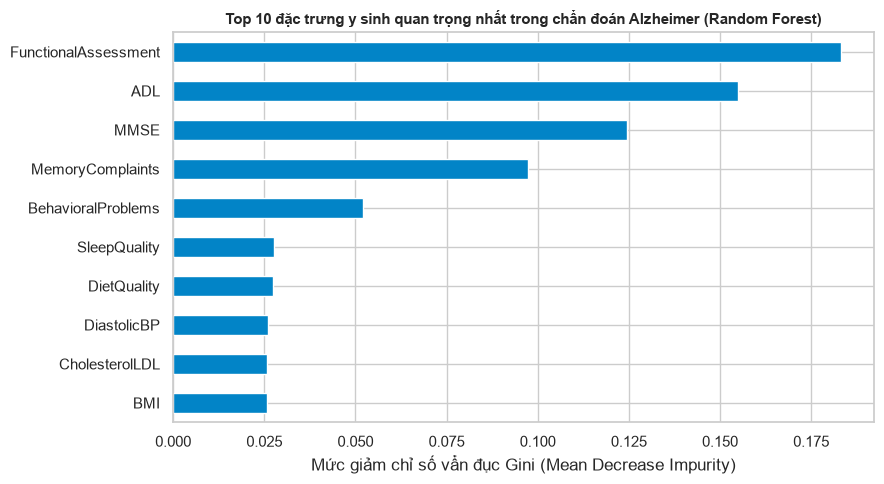

Đã lưu mô hình tốt nhất vào 'models/best_rf.joblib' và scaler vào 'models/scaler.joblib'


In [10]:
# ==============================================================================
# YÊU CẦU 10: Phân tích mức độ quan trọng đặc trưng (Feature Importance) 
# và lưu trữ mô hình tối ưu.
# ==============================================================================
import joblib

# 1. Trực quan hoá Top 10 đặc trưng quan trọng nhất của Random Forest
feature_names = list(X.columns)
importances = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
importances.head(10).plot(kind='barh', color='#0284c7')
plt.title('Top 10 đặc trưng y sinh quan trọng nhất trong chẩn đoán Alzheimer (Random Forest)', fontsize=11, weight='bold')
plt.xlabel('Mức giảm chỉ số vẩn đục Gini (Mean Decrease Impurity)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 2. Lưu trữ mô hình tối ưu và bộ chuẩn hóa Scaler
joblib.dump(rf_model, 'models/best_rf.joblib')
joblib.dump(scaler, 'models/scaler.joblib')
print("Đã lưu mô hình tốt nhất vào 'models/best_rf.joblib' và scaler vào 'models/scaler.joblib'")


In [11]:
# ==============================================================================
# YÊU CẦU 11: Tiến hành testing dự đoán với các hồ sơ bệnh nhân cụ thể
# (Dạng như yêu cầu 6 bài 1 và yêu cầu 8 bài 5 trong tài liệu code mẫu)
# ==============================================================================

# 1. Tạo hồ sơ bệnh nhân cụ thể 1: Người cao tuổi nguy cơ cao (Suy giảm nhận thức nặng)
# Điểm MMSE thấp = 12.0, ADL thấp = 2.5, FuncAssess = 3.0, Có biểu hiện suy giảm trí nhớ & hay quên
sample_patient_high_risk = X_test.iloc[0:1].copy()
sample_patient_high_risk['Age'] = 82
sample_patient_high_risk['MMSE'] = 12.0
sample_patient_high_risk['ADL'] = 2.5
sample_patient_high_risk['FunctionalAssessment'] = 3.0
sample_patient_high_risk['MemoryComplaints'] = 1
sample_patient_high_risk['BehavioralProblems'] = 1
sample_patient_high_risk['Confusion'] = 1

# 2. Tạo hồ sơ bệnh nhân cụ thể 2: Người cao tuổi khỏe mạnh
# Điểm MMSE cao = 28.5, ADL cao = 9.2, FuncAssess = 8.8, Không có triệu chứng thần kinh
sample_patient_low_risk = X_test.iloc[1:2].copy()
sample_patient_low_risk['Age'] = 68
sample_patient_low_risk['MMSE'] = 28.5
sample_patient_low_risk['ADL'] = 9.2
sample_patient_low_risk['FunctionalAssessment'] = 8.8
sample_patient_low_risk['MemoryComplaints'] = 0
sample_patient_low_risk['BehavioralProblems'] = 0
sample_patient_low_risk['Confusion'] = 0

# 3. Chuẩn hóa dữ liệu đầu vào bằng scaler đã huấn luyện
p1_scaled = scaler.transform(sample_patient_high_risk)
p2_scaled = scaler.transform(sample_patient_low_risk)

# 4. Dự đoán bằng mô hình Random Forest
pred_p1 = rf_model.predict(p1_scaled)[0]
prob_p1 = rf_model.predict_proba(p1_scaled)[0][1]

pred_p2 = rf_model.predict(p2_scaled)[0]
prob_p2 = rf_model.predict_proba(p2_scaled)[0][1]

print("=== KẾT QUẢ DỰ ĐOÁN THỬ NGHIỆM TRÊN BỆNH NHÂN CỤ THỂ ===")
print("\n[BỆNH NHÂN 1] - 82 tuổi, MMSE: 12.0/30, ADL: 2.5/10, Giảm trí nhớ: Có")
print(f"-> Dự đoán nhãn: {pred_p1} ({'MẮC BỆNH ALZHEIMER' if pred_p1 == 1 else 'KHÔNG MẮC BỆNH'})")
print(f"-> Xác suất mắc bệnh: {prob_p1*100:.2f}%")

print("\n[BỆNH NHÂN 2] - 68 tuổi, MMSE: 28.5/30, ADL: 9.2/10, Giảm trí nhớ: Không")
print(f"-> Dự đoán nhãn: {pred_p2} ({'MẮC BỆNH ALZHEIMER' if pred_p2 == 1 else 'KHÔNG MẮC BỆNH / KHỎE MẠNH'})")
print(f"-> Xác suất mắc bệnh: {prob_p2*100:.2f}%")


=== KẾT QUẢ DỰ ĐOÁN THỬ NGHIỆM TRÊN BỆNH NHÂN CỤ THỂ ===

[BỆNH NHÂN 1] - 82 tuổi, MMSE: 12.0/30, ADL: 2.5/10, Giảm trí nhớ: Có
-> Dự đoán nhãn: 1 (MẮC BỆNH ALZHEIMER)
-> Xác suất mắc bệnh: 87.50%

[BỆNH NHÂN 2] - 68 tuổi, MMSE: 28.5/30, ADL: 9.2/10, Giảm trí nhớ: Không
-> Dự đoán nhãn: 0 (KHÔNG MẮC BỆNH / KHỎE MẠNH)
-> Xác suất mắc bệnh: 4.50%
